# Базовая обработка текста и классификация
## Семинар 1 · 24 октября 2026
**Алан-Барсаг Газзаев**

Блок «Основы NLP и векторные представления».

В этом notebook мы построим классификатор русскоязычных запросов к голосовому
помощнику. Один запрос соответствует одному `intent`: например, создать
событие в календаре, узнать погоду или включить музыку. Мы последовательно
пройдём загрузку данных, preprocessing, построение features, обучение
Logistic Regression и анализ ошибок.

Главное сравнение — **TF-IDF + Logistic Regression** и **pretrained sentence
embeddings + Logistic Regression**. Одинаковые train/dev/test и одна семья
classifier позволяют обсуждать влияние representation. При этом pretrained
encoder уже использовал внешние данные: это сравнение двух практических
решений, а не эксперимент с одинаковым объёмом pretraining.

Весь материал семинара находится здесь: объяснения, рабочий код, задания,
графики, вопросы для обсуждения и решения. Для чтения доступны сохранённые
outputs проверенного запуска; для собственных экспериментов выполните notebook
с начала в чистом kernel.

## Как работать с notebook

Основной маршрут рассчитан примерно на **90 минут** при заранее подготовленном
окружении. Загрузка библиотек и модели выполняется до занятия.

| Этап | Время | Результат |
|---|---:|---|
| Постановка задачи, данные и split | 15 мин | Понимание `text`, `label`, train/dev/test |
| Tokenization, stop words, stemming, lemmatization | 20 мин | Сравнение NLTK и spaCy |
| TF-IDF и Logistic Regression | 20 мин | Рабочий lexical baseline |
| Sentence embeddings и классификатор | 20 мин | Второе решение на том же split |
| Сравнение и error analysis | 15 мин | Выводы по метрикам и примерам |

Разделы 12–14 — дополнительный материал: упражнения, retrieval и сохранение
результата. Их можно разобрать после основного маршрута.

**Порядок:** выполняйте code cells сверху вниз. Перед заданием сначала
сформулируйте ожидаемый результат, затем запустите пример. Все ячейки содержат
завершённый код: `Run all` не останавливается на `TODO` или пропущенных функциях.
Меняя решение, работайте с train/dev; test используется в разделе 9 после
фиксации настроек.

**Навигация:** [окружение](#environment) · [данные](#data) ·
[split](#split) · [preprocessing](#preprocessing) · [TF-IDF](#tfidf) ·
[classifier](#classifier) · [embeddings](#embeddings) ·
[сравнение](#evaluation) · [ошибки](#errors) · [упражнения](#exercises).

<a id="environment"></a>
## 1. Окружение и запуск

Notebook предназначен для **Python 3.10–3.12** в Jupyter или Google Colab.
Для Colab загрузите этот `.ipynb` через «Файл → Открыть блокнот → Загрузить».

**Первый запуск в Google Colab:**

1. В меню «Среда выполнения → Сменить среду выполнения» выберите версию
   **2026.07 (Python 3.12)**. Для ускорения embeddings можно выбрать **T4 GPU**.
2. Выполните **только первую code cell** с установкой библиотек, расположенную ниже.
   Дождитесь сообщения «Установка завершена».
3. Выберите «Среда выполнения → Перезапустить сеанс и выполнить весь код»
   и подтвердите перезапуск. После этого notebook последовательно выполнится с начала.

Colab может загрузить NumPy ещё до выполнения пользовательских ячеек.
Поэтому после первой установки зафиксированных версий **перезапуск обязателен**:
иначе возможен ImportError из-за смешения старых и новых компонентов NumPy.
Установленные библиотеки остаются на диске, а переменные kernel очищаются.
При последующих запусках без изменения версий достаточно «Выполнить всё».
При подключении новой среды повторите шаги установки и перезапуска.

GPU ускоряет вычисление embeddings; основная логика также допускает CPU.
Для полного прохода достаточно обычного учебного GPU, большая LLM не нужна.

При первом запуске потребуется интернет: загрузятся Python packages, русская
модель spaCy, NLTK stop words, архив MASSIVE и multilingual encoder.
Предусмотрите несколько гигабайт свободного места. Данные и промежуточные
результаты сохраняются в `seminar_work` рядом с рабочим каталогом kernel.
Платные API и токены доступа не используются.

Первая code cell устанавливает зафиксированные версии учебных библиотек.
PyTorch используется из окружения, если он уже установлен в версии 2.6 или
новее. В новом Jupyter-окружении без PyTorch установится версия 2.8.0.
Для нестандартной CUDA-конфигурации PyTorch лучше установить заранее по
[официальной инструкции](https://pytorch.org/get-started/locally/).

Запускайте установку **до остальных imports**. В Jupyter после изменения
версий уже загруженных библиотек также перезапустите kernel и выполните notebook
с начала. После успешной установки `INSTALL_PACKAGES` можно переключить в `False`
до подключения новой среды.

In [1]:
import sys
import subprocess
import importlib.metadata as metadata

assert (3, 10) <= sys.version_info[:2] <= (3, 12), "Используйте Python 3.10–3.12."
INSTALL_PACKAGES = True
PACKAGES = {
    "numpy": "2.2.6", "pandas": "2.2.3", "scipy": "1.15.3",
    "scikit-learn": "1.7.2", "nltk": "3.9.2", "spacy": "3.8.7",
    "sentence-transformers": "5.1.2", "transformers": "4.57.1",
    "huggingface-hub": "0.35.3", "tokenizers": "0.22.1",
    "matplotlib": "3.10.7", "requests": "2.32.5",
}

def installed_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None

if INSTALL_PACKAGES:
    missing = [f"{name}=={version}" for name, version in PACKAGES.items()
               if installed_version(name) != version]
    if installed_version("torch") is None:
        missing.append("torch==2.8.0")
    if installed_version("ru-core-news-sm") != "3.8.0":
        missing.append(
            "https://github.com/explosion/spacy-models/releases/download/"
            "ru_core_news_sm-3.8.0/ru_core_news_sm-3.8.0-py3-none-any.whl"
        )
    if missing:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("Установка завершена. Если библиотеки уже импортировались, перезапустите kernel.")
else:
    print("Установка пропущена; используются библиотеки текущего окружения.")

Установка завершена. Если библиотеки уже импортировались, перезапустите kernel.


### 1.1. Imports, reproducibility и небольшие ограничения ресурсов

`SEED` фиксирует выбор учебной подвыборки и настройки случайных процедур.
Это не обещает побитовую идентичность на любом железе: версии библиотек,
PyTorch и CUDA также влияют на результат. Поэтому notebook печатает версии
и сохраняет manifest запуска.

Для демонстрации достаточно двух CPU threads. Сначала используем CPU для
NLTK, spaCy и scikit-learn, затем автоматически выберем CUDA для encoder,
если она доступна. `warnings` о несходимости Logistic Regression не скрываются:
это полезный сигнал о необходимости проверить данные и `max_iter`.

In [2]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

import re
import json
import random
import hashlib
import tarfile
import unicodedata
from pathlib import Path
from time import perf_counter
from itertools import combinations

import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import requests
import nltk
import spacy
import torch
from nltk.tokenize import wordpunct_tokenize
from nltk.stem import SnowballStemmer
from nltk.corpus import stopwords
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay,
)
from sentence_transformers import SentenceTransformer
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
assert tuple(int(v) for v in torch.__version__.split("+")[0].split(".")[:2]) >= (2, 6)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WORK_DIR = Path("seminar_work")
CACHE_DIR = WORK_DIR / "cache"
RESULT_DIR = WORK_DIR / "results"
for directory in (CACHE_DIR, RESULT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 25)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
versions = {name: installed_version(name) for name in [*PACKAGES, "torch", "ru-core-news-sm"]}
print("Python:", sys.version.split()[0], "| device:", DEVICE)
display(pd.Series(versions, name="version").to_frame())

/usr/local/lib/python3.12/dist-packages/torch/cuda/__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.3 | device: cuda


,version
numpy,2.2.6
pandas,2.2.3
scipy,1.15.3
scikit-learn,1.7.2
nltk,3.9.2
spacy,3.8.7
sentence-transformers,5.1.2
transformers,4.57.1
huggingface-hub,0.35.3
tokenizers,0.22.1


<a id="data"></a>
## 2. Датасет и формулировка задачи

Используем русскоязычную часть **MASSIVE 1.1**, созданного Amazon на основе
локализации запросов SLURP. В исходном corpus размечены intents и slots.
На семинаре решаем только **single-label intent classification**:
входом является `utt`, целевой меткой — `intent`.

Берём восемь intents. Среди них есть близкие пары: `alarm_set` и
`alarm_query`, `calendar_set` и `calendar_query`. Поэтому тематического
слова «будильник» или «календарь» не всегда достаточно — нужно различать
запрашиваемое действие. Имена labels остаются английскими.

| Intent | Что хочет пользователь |
|---|---|
| `alarm_set` | Установить будильник |
| `alarm_query` | Узнать информацию о будильнике |
| `calendar_set` | Добавить событие в календарь |
| `calendar_query` | Посмотреть события |
| `play_music` | Включить музыку |
| `weather_query` | Узнать погоду |
| `news_query` | Получить новости |
| `transport_query` | Получить транспортную информацию |

Это **учебная подвыборка**, а не официальный результат на полном MASSIVE:
число classes уменьшено, число примеров ограничено, дубликаты обработаны
по правилам ниже. Реальная система должна также обрабатывать запросы вне
этих восьми intents; текущий classifier всегда выбирает один из известных.

Источники: [официальный repository](https://github.com/alexa/massive),
[MASSIVE paper](https://arxiv.org/abs/2204.08582),
[SLURP paper](https://aclanthology.org/2020.emnlp-main.588/).
Данные MASSIVE распространяются по **CC BY 4.0**; атрибуция:
Amazon.com Inc. or its affiliates; FitzGerald et al., 2022.
Учебные изменения — выбор языка/classes, удаление повторов и ограничение
размера. Работаем с текстом `utt`, а не с `annot_utt`: последний содержит
дополнительную разметку, которой не будет у нового запроса.

### 2.1. Загрузка официального архива

Вместо dataset loading script используем непосредственно JSONL из
версионированного архива. Так загрузка не зависит от поддержки сторонних
Python scripts в `datasets`.

Архив скачивается один раз. Проверяется SHA-256 именно того файла, на котором
подготовлен notebook. Из архива читается только `ru-RU.jsonl`; остальные
языки не распаковываются. Если загрузка оборвалась, итоговый файл не заменяется
незавершённым содержимым.

In [3]:
DATA_URL = "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.1.tar.gz"
ARCHIVE_SHA256 = "4cba5faa11c71437928e17cb1b9b3d8b8e727e7ea363a3a9a8045e19c0491577"
ARCHIVE_PATH = CACHE_DIR / "amazon-massive-dataset-1.1.tar.gz"

def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

if not ARCHIVE_PATH.exists():
    temporary = ARCHIVE_PATH.with_suffix(".download")
    with requests.get(DATA_URL, stream=True, timeout=(20, 180)) as response:
        response.raise_for_status()
        with temporary.open("wb") as f:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                f.write(chunk)
    assert sha256_file(temporary) == ARCHIVE_SHA256, "Checksum архива не совпадает."
    temporary.replace(ARCHIVE_PATH)

assert sha256_file(ARCHIVE_PATH) == ARCHIVE_SHA256, (
    "Checksum не совпадает. Проверьте файл; при повреждении удалите только этот архив и повторите загрузку."
)
with tarfile.open(ARCHIVE_PATH, "r:gz") as archive:
    matches = [m for m in archive.getmembers()
               if m.isfile() and m.name.endswith("/data/ru-RU.jsonl")]
    assert len(matches) == 1
    raw_bytes = archive.extractfile(matches[0]).read()

records = [json.loads(line) for line in raw_bytes.decode("utf-8").splitlines() if line.strip()]
raw = pd.DataFrame(records)[["id", "locale", "partition", "utt", "intent"]].copy()
raw = raw.rename(columns={"utt": "text", "intent": "label"})
raw["id"] = raw["id"].astype(str)
assert raw["locale"].eq("ru-RU").all()
assert set(raw["partition"]) == {"train", "dev", "test"}
assert raw["id"].is_unique
print("Русскоязычных записей:", len(raw))
print("SHA-256 ru-RU.jsonl:", hashlib.sha256(raw_bytes).hexdigest())
display(raw.loc[raw["partition"].eq("train"), ["id", "text", "label"]].head())

Русскоязычных записей: 16521
SHA-256 ru-RU.jsonl: af7367861ea21c1d69a084b290145815f7eaf82dcdc43b7ab572b993f9b2a69d


,id,text,label
1,1,разбуди меня в девять утра в пятницу,alarm_set
2,2,поставь будильник на два часа вперед,alarm_set
4,4,олли тихо,audio_volume_mute
5,5,отстановись,audio_volume_mute
6,6,олли остановись на десять секунд,audio_volume_mute


<a id="split"></a>
## 3. Train/dev/test и контроль повторов

Сохраняем исходные `partition` из MASSIVE:

- **train** используется для vocabulary, IDF и weights classifier;
- **dev** используется для выбора `C` и исследования preprocessing;
- **test** используется для итоговой оценки после выбора параметров.

Сначала удаляем пустые строки и точные повторы после технической
нормализации Unicode, регистра и пробелов. Эта нормализация создаёт
`duplicate_key` только для поиска повторов — исходный `text` сохраняется.
Если в train одна запись имеет разные labels, исключаем такой ключ из всех
частей: противоречие обнаруживается только по training labels.

При совпадении ключей между split отдаём приоритет train, затем dev:
повторная запись исключается из более позднего split. Это правило меняет
состав исходного benchmark, поэтому наши оценки нельзя непосредственно
сравнивать с leaderboard MASSIVE. Оно также не удаляет все paraphrases:
«точных повторов нет» не означает полного отсутствия семантического сходства.

In [4]:
TARGET_INTENTS = [
    "alarm_set", "alarm_query", "calendar_set", "calendar_query",
    "play_music", "weather_query", "news_query", "transport_query",
]
CAP_PER_CLASS = {"train": 200, "dev": 50, "test": 80}
LABELS = sorted(TARGET_INTENTS)

def duplicate_key(text):
    return " ".join(unicodedata.normalize("NFKC", str(text)).casefold().split())

data = raw[raw["label"].isin(TARGET_INTENTS)].copy()
data = data.dropna(subset=["text", "label"])
data = data[data["text"].str.strip().ne("")].copy()
data["duplicate_key"] = data["text"].map(duplicate_key)

train_label_counts = (
    data.loc[data["partition"].eq("train")]
    .groupby("duplicate_key")["label"].nunique()
)
ambiguous_train_keys = set(train_label_counts[train_label_counts > 1].index)
data = data[~data["duplicate_key"].isin(ambiguous_train_keys)].copy()

splits = {}
seen_keys = set()
audit_rows = []
for part in ("train", "dev", "test"):
    frame = data.loc[data["partition"].eq(part)].sort_values("id").copy()
    before = len(frame)
    frame = frame.drop_duplicates("duplicate_key")
    frame = frame[~frame["duplicate_key"].isin(seen_keys)]
    after_dedup = len(frame)
    # Учитываем ключи всей очищенной части, даже если часть строк не попадёт под cap.
    seen_keys.update(frame["duplicate_key"])
    sampled = []
    for label in LABELS:
        group = frame[frame["label"].eq(label)]
        assert len(group) > 0, f"Нет данных: {part}, {label}"
        sampled.append(group.sample(n=min(len(group), CAP_PER_CLASS[part]), random_state=SEED))
    splits[part] = (
        pd.concat(sampled).sample(frac=1, random_state=SEED).reset_index(drop=True)
    )
    audit_rows.append({"split": part, "before": before, "after_dedup": after_dedup,
                       "selected": len(splits[part])})

train_df, dev_df, test_df = (splits[p] for p in ("train", "dev", "test"))
for left, right in combinations(splits, 2):
    assert set(splits[left]["id"]).isdisjoint(splits[right]["id"])
    assert set(splits[left]["duplicate_key"]).isdisjoint(splits[right]["duplicate_key"])
assert all(set(frame["label"]) == set(LABELS) for frame in splits.values())
print("Противоречивых keys в train:", len(ambiguous_train_keys))
display(pd.DataFrame(audit_rows).set_index("split"))

Противоречивых keys в train: 1


,before,after_dedup,selected
split,,,
train,3628,3532,1498
dev,650,607,334
test,917,851,517


### 3.1. Размеры classes и длины текстов

`cap` задаёт верхнюю границу числа примеров каждого класса. Если исходных
примеров меньше, берём все доступные: распределение не обязано стать строго
равномерным. Для выбора модели используем **macro-F1**, чтобы каждый class
вносил одинаковый вес. Accuracy дополняет, но не заменяет эту оценку.

Сейчас рассматриваем только агрегированные размеры split и примеры train.
Тексты ошибок test будут доступны после финального сравнения.

,train,dev,test
label,,,
alarm_query,123,19,33
alarm_set,175,30,33
calendar_query,200,50,80
calendar_set,200,50,80
news_query,200,50,80
play_music,200,50,80
transport_query,200,35,51
weather_query,200,50,80


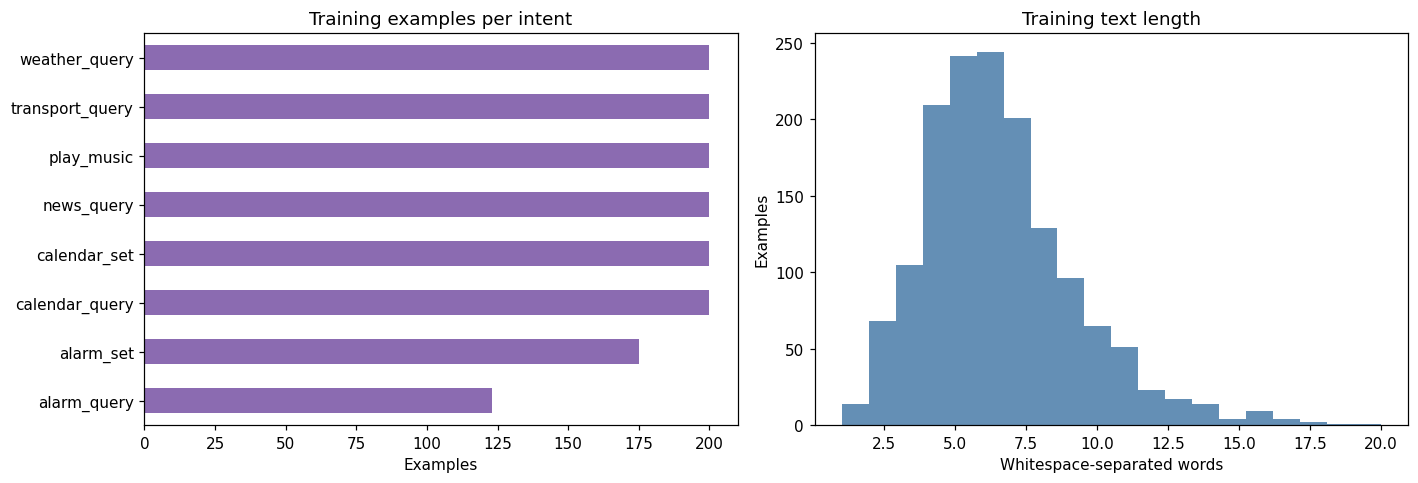

,text,label
0,хочу послушать песню один,play_music
1,найди прогноз о скорости ветра сегодня вечером,weather_query
4,olly какие последние известия касательно урагана катрина,news_query
8,когда и где будет юлин день рождения,calendar_query
9,поставь будильник на полдень завтра,alarm_set
11,можешь сказать мне время поезда который идёт в москву из екатеринбурга,transport_query
14,покажи мне все заведенные будильники,alarm_query
40,пожалуйста поставь ежемесячное напоминание оплатить аренду,calendar_set


In [5]:
counts = pd.DataFrame({
    part: frame["label"].value_counts().reindex(LABELS, fill_value=0)
    for part, frame in splits.items()
})
display(counts)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
counts["train"].plot.barh(ax=axes[0], color="#8b6bb1")
axes[0].set(title="Training examples per intent", xlabel="Examples", ylabel="")
train_df["text"].str.split().str.len().plot.hist(bins=20, ax=axes[1], color="#648fb5")
axes[1].set(title="Training text length", xlabel="Whitespace-separated words", ylabel="Examples")
plt.tight_layout()
plt.show()
display(train_df.groupby("label", sort=True).head(1)[["text", "label"]])

**Вопросы перед preprocessing**

1. Чем `alarm_query` отличается от `alarm_set`? Какие слова могут помогать?
2. Почему IDF нельзя оценить по объединению train и test?
3. Можно ли использовать `label` как дополнительный вход для encoder?
4. Что произойдёт, если один и тот же запрос окажется и в train, и в test?

Ответ на третий вопрос — нет: label является искомым ответом. Новый
пользовательский запрос его не содержит. По той же причине исключены
`annot_utt` и другая дополнительная разметка.

<a id="preprocessing"></a>
## 4. Preprocessing: NLTK и spaCy

Preprocessing — часть модели. Он может сокращать vocabulary и объединять
словоформы, но также удалять полезную информацию. Для русских запросов важны
частицы, числа, названия и форма действия. «Поставь будильник» и «не ставь
будильник» отличаются одним словом.

**NLTK** удобен для отдельных операций и учебного анализа: tokenization,
списки stop words, stemming. **spaCy** предоставляет языковой pipeline и
объекты `Doc`/`Token`: tokenization, morphosyntactic annotations и
lemmatization. `spacy.blank("ru")` создаёт tokenizer, но не заменяет
обученную языковую модель.

Ниже используются небольшие авторские примеры, не входящие в test set.
Результаты preprocessing обсуждаем отдельно от качества classifier.

In [6]:
EXAMPLE = "Не ставь будильник на 07:30! Перенеси встречу на 24 октября."
wordpunct_tokens = wordpunct_tokenize(EXAMPLE)
display(pd.DataFrame({"position": range(len(wordpunct_tokens)), "token": wordpunct_tokens}))

,position,token
0,0,Не
1,1,ставь
2,2,будильник
3,3,на
4,4,07
5,5,:
6,6,30
7,7,!
8,8,Перенеси
9,9,встречу


### 4.1. Что делает tokenizer

`wordpunct_tokenize` отделяет группы букв/цифр и punctuation по правилам.
Для него не требуется модель `punkt`. Это удобно для демонстрации, но
полученное разбиение не обязательно совпадает с tokenization spaCy или
subword tokenizer encoder.

Обратите внимание на `07:30`: единый момент времени превращается в несколько
элементов. Решение сохранить число, заменить его placeholder или разбить
зависит от задачи. Для intent classification точное время часто не является
label, но в slot filling оно уже может быть центральной частью ответа.

In [7]:
# spaCy остаётся на CPU; GPU ниже используется только для sentence encoder.
spacy.require_cpu()
nlp = spacy.load("ru_core_news_sm", disable=["ner", "parser"])
doc = nlp(EXAMPLE)
display(pd.DataFrame([
    {"token": token.text, "lemma": token.lemma_, "POS": token.pos_,
     "is_stop": token.is_stop, "is_punct": token.is_punct}
    for token in doc
]))
print("Активные компоненты:", nlp.pipe_names)

,token,lemma,POS,is_stop,is_punct
0,Не,не,PART,True,False
1,ставь,ставь,VERB,False,False
2,будильник,будильник,NOUN,False,False
3,на,на,ADP,True,False
4,07:30,07:30,NUM,False,False
5,!,!,PUNCT,False,True
6,Перенеси,перенести,VERB,False,False
7,встречу,встреча,NOUN,False,False
8,на,на,ADP,True,False
9,24,24,ADJ,False,False


Активные компоненты: ['tok2vec', 'morphologizer', 'attribute_ruler', 'lemmatizer']


### 4.2. Stemming и lemmatization

Stemming применяет правила сокращения слов; результат может не быть словом
языка. Lemmatization пытается вернуть lemma с учётом языковых ресурсов и,
в зависимости от pipeline, контекста. Поэтому эти операции не взаимозаменяемы.

Сравните несколько словоформ. Проверяйте фактический output, а не
предполагайте, что все формы всегда объединятся правильно. Для коротких
запросов неоднозначность остаётся даже у языковой модели.

In [8]:
stemmer = SnowballStemmer("russian")
morph_examples = ["машина", "машины", "машинами", "лучше", "встречи", "поставь"]
lemma_docs = list(nlp.pipe(morph_examples, batch_size=32))
display(pd.DataFrame({
    "word": morph_examples,
    "stem": [stemmer.stem(word) for word in morph_examples],
    "lemma": [" ".join(token.lemma_ for token in doc) for doc in lemma_docs],
}))

,word,stem,lemma
0,машина,машин,машина
1,машины,машин,машина
2,машинами,машин,машина
3,лучше,лучш,хороший
4,встречи,встреч,встреча
5,поставь,постав,поставить


### 4.3. Stop words и сохранение отрицания

Готовый список stop words — языковой ресурс, а не перечень бесполезных для
любой задачи слов. Сначала посмотрим, входят ли в него `не`, `ни`, `нет`.
Затем сравним результат стандартного удаления и варианта с сохранением
отрицания.

В основном TF-IDF baseline ниже **не удаляем stop words автоматически**.
Это простое воспроизводимое решение. Изменение списка можно проверить на dev
как отдельную гипотезу. Sentence encoder получает исходные фразы: его
tokenizer и pretraining рассчитаны на естественную последовательность.

In [9]:
NLTK_DIR = CACHE_DIR / "nltk_data"
NLTK_DIR.mkdir(parents=True, exist_ok=True)
nltk.data.path.insert(0, str(NLTK_DIR))
try:
    nltk.data.find("corpora/stopwords")
except LookupError:
    if not nltk.download("stopwords", download_dir=str(NLTK_DIR), quiet=True):
        raise RuntimeError("Не удалось загрузить NLTK stopwords. Проверьте интернет.")
ru_stopwords = set(stopwords.words("russian"))
negations = {"не", "ни", "нет"}
safe_stopwords = ru_stopwords - negations

def remove_stopwords(text, stop_list):
    return " ".join(token for token in wordpunct_tokenize(text.lower())
                    if token not in stop_list)

negation_examples = ["Ставь будильник", "Не ставь будильник", "Нет встреч сегодня"]
display(pd.DataFrame({
    "original": negation_examples,
    "default_stopwords": [remove_stopwords(t, ru_stopwords) for t in negation_examples],
    "keep_negations": [remove_stopwords(t, safe_stopwords) for t in negation_examples],
}))
print("Отрицания в стандартном списке:", sorted(negations & ru_stopwords))

,original,default_stopwords,keep_negations
0,Ставь будильник,ставь будильник,ставь будильник
1,Не ставь будильник,ставь будильник,не ставь будильник
2,Нет встреч сегодня,встреч сегодня,нет встреч сегодня


Отрицания в стандартном списке: ['не', 'нет', 'ни']


### 4.4. Batch processing и подготовка lemmas

`nlp.pipe` обрабатывает коллекцию текстов последовательно небольшими batches.
Для lemmatized-варианта убираем punctuation и пробельные tokens, сохраняем
цифры и stop words. Это явно заданное решение, а не «универсальная очистка».

Дальше сравним lemmatization с raw-text TF-IDF **на dev**. Предобученная
spaCy не переобучается на наших split, поэтому применение её pipeline к dev
не означает обучения на dev. Однако выбор самого preprocessing по dev
является частью model selection.

In [10]:
def lemmatize_texts(texts):
    result = []
    for doc in nlp.pipe(list(texts), batch_size=64):
        words = [(token.lemma_ or token.text).lower()
                 for token in doc if not token.is_space and not token.is_punct]
        result.append(" ".join(words))
    return result

t0 = perf_counter()
train_lemmas = lemmatize_texts(train_df["text"])
dev_lemmas = lemmatize_texts(dev_df["text"])
lemma_seconds = perf_counter() - t0
display(pd.DataFrame({
    "original": train_df["text"].head(6),
    "lemmas": train_lemmas[:6],
}))
print(f"Lemmatization train+dev: {lemma_seconds:.2f} s")

,original,lemmas
0,хочу послушать песню один,хотеть послушать песня один
1,найди прогноз о скорости ветра сегодня вечером,найди прогноз о скорость ветер сегодня вечер
2,какой прогноз погоды на эти выходные,какой прогноз погода на этот выходной
3,мне нанести солнцезащитный крем,мне нанести солнцезащитный крем
4,olly какие последние известия касательно урагана катрина,olly какой последний известие касательно ураган катрина
5,расскажи мне последние новости из ростова на дону,рассказать мне последний новость из ростов на дон


Lemmatization train+dev: 4.54 s


<a id="tfidf"></a>
## 5. TF-IDF: от tokens к sparse matrix

Сначала используем маленькую коллекцию, не связанную с evaluation.
Строка matrix соответствует документу, столбец — feature. Features могут
быть отдельными words, word n-grams или character n-grams.

`fit` создаёт vocabulary и оценивает IDF. `transform` использует уже
зафиксированные vocabulary и IDF. `fit_transform` совмещает эти операции,
поэтому на test вызывается только `transform`.

В scikit-learn по умолчанию IDF сглаживается, а строки TF-IDF нормализуются.
Вес не следует интерпретировать как вероятность class или абсолютную
«важность слова». Он описывает term относительно выбранного corpus и
настроек vectorizer.

In [11]:
toy_texts = ["поставь будильник", "проверь будильник", "поставь встречу"]
toy_count = CountVectorizer(token_pattern=r"(?u)\b\w+\b")
toy_counts = toy_count.fit_transform(toy_texts)
display(pd.DataFrame(toy_counts.toarray(), columns=toy_count.get_feature_names_out(),
                     index=toy_texts))

toy_tfidf = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")
toy_matrix = toy_tfidf.fit_transform(toy_texts)
display(pd.DataFrame(toy_matrix.toarray(), columns=toy_tfidf.get_feature_names_out(),
                     index=toy_texts).round(3))
display(pd.DataFrame({"feature": toy_tfidf.get_feature_names_out(),
                      "idf": toy_tfidf.idf_}).round(3))

,будильник,встречу,поставь,проверь
поставь будильник,1,0,1,0
проверь будильник,1,0,0,1
поставь встречу,0,1,1,0


,будильник,встречу,поставь,проверь
поставь будильник,0.707,0.000,0.707,0.000
проверь будильник,0.605,0.000,0.000,0.796
поставь встречу,0.000,0.796,0.605,0.000


,feature,idf
0,будильник,1.288
1,встречу,1.693
2,поставь,1.288
3,проверь,1.693


### 5.1. N-grams, vocabulary и неизвестные слова

Unigrams учитывают присутствие отдельных слов. Bigrams сохраняют локальное
соседство: `поставь будильник` и `проверь будильник` становятся разными
features. Они не кодируют всю структуру предложения, а vocabulary становится
больше.

Feature, отсутствовавший во время `fit`, не получает отдельную координату при
`transform`. Если в новом тексте не осталось известных features, строка
может стать нулевой. Classifier всё равно способен вернуть class по своим
параметрам; это не означает, что текст был содержательно распознан.

In [12]:
toy_bigrams = TfidfVectorizer(ngram_range=(1, 2), token_pattern=r"(?u)\b\w+\b")
toy_bigrams.fit(toy_texts)
print("Features:", toy_bigrams.get_feature_names_out().tolist())
unknown_texts = ["поставь будильник завтра", "абракадабра"]
unknown_matrix = toy_bigrams.transform(unknown_texts)
display(pd.DataFrame({"text": unknown_texts, "nonzero_features": unknown_matrix.getnnz(axis=1)}))

Features: ['будильник', 'встречу', 'поставь', 'поставь будильник', 'поставь встречу', 'проверь', 'проверь будильник']


,text,nonzero_features
0,поставь будильник завтра,3
1,абракадабра,0


### 5.2. TF-IDF на training data

Настройки основного baseline:

| Параметр | Значение | Смысл |
|---|---|---|
| `ngram_range` | `(1, 2)` | Words и соседние пары |
| `min_df` | `2` | Feature встречается хотя бы в двух training documents |
| `max_features` | `20_000` | Ограничение размера vocabulary |
| `sublinear_tf` | `True` | Логарифмическая шкала ненулевой term frequency |
| `norm` | `"l2"` | Нормализация каждой строки |
| `token_pattern` | Words длины от одного символа | Сохраняются короткие русские слова |

`min_df` и vocabulary оцениваются только по train. Матрицу большого corpus
оставляем sparse; `.toarray()` использовался выше только для маленького
учебного примера.

In [13]:
def make_vectorizer():
    return TfidfVectorizer(
        ngram_range=(1, 2), min_df=2, max_features=20_000,
        sublinear_tf=True, norm="l2", token_pattern=r"(?u)\b\w+\b",
    )

X_train = train_df["text"].tolist()
X_dev = dev_df["text"].tolist()
y_train = train_df["label"].to_numpy()
y_dev = dev_df["label"].to_numpy()

vectorizer = make_vectorizer()
t0 = perf_counter()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_dev_tfidf = vectorizer.transform(X_dev)
tfidf_feature_seconds = perf_counter() - t0

def sparse_megabytes(matrix):
    return (matrix.data.nbytes + matrix.indices.nbytes + matrix.indptr.nbytes) / 1024**2

display(pd.DataFrame([
    {"split": "train", "rows": X_train_tfidf.shape[0],
     "features": X_train_tfidf.shape[1], "nnz": X_train_tfidf.nnz,
     "matrix_MiB": sparse_megabytes(X_train_tfidf)},
    {"split": "dev", "rows": X_dev_tfidf.shape[0],
     "features": X_dev_tfidf.shape[1], "nnz": X_dev_tfidf.nnz,
     "matrix_MiB": sparse_megabytes(X_dev_tfidf)},
]).round(3))
print("Нулевых dev-строк:", int((X_dev_tfidf.getnnz(axis=1) == 0).sum()))

,split,rows,features,nnz,matrix_MiB
0,train,1498,1786,12726,0.151
1,dev,334,1786,2526,0.030


Нулевых dev-строк: 1


<a id="classifier"></a>
## 6. Logistic Regression и model selection

Logistic Regression обучает связь между features и class labels.
Для multiclass задачи выход содержит scores/probabilities известных classes,
а `predict` выбирает один из них. Это supervised learning: наличие готовых
features не устраняет необходимость training labels.

`C` регулирует силу regularization: меньшее `C` соответствует более сильной
regularization. Не существует значения, оптимального для всех
representations. Для двух основных решений проверяем одинаковую небольшую
сетку `C = [0.1, 1, 10]`. Выбор делаем по dev macro-F1; при равенстве
остаётся первое, меньшее `C`.

Перед обучением сравнимся с `DummyClassifier`: он не использует содержание
текста. Этот контроль помогает понять, какое качество даёт только
распределение labels.

In [14]:
def metric_row(name, truth, prediction):
    return {
        "model": name,
        "accuracy": accuracy_score(truth, prediction),
        "macro_F1": f1_score(truth, prediction, labels=LABELS, average="macro", zero_division=0),
        "weighted_F1": f1_score(truth, prediction, labels=LABELS, average="weighted", zero_division=0),
    }

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(np.zeros((len(y_train), 1)), y_train)
dummy_dev = dummy.predict(np.zeros((len(y_dev), 1)))
display(pd.DataFrame([metric_row("Dummy / dev", y_dev, dummy_dev)]).round(4))

,model,accuracy,macro_F1,weighted_F1
0,Dummy / dev,0.1497,0.0326,0.039


### 6.1. Подбор `C` для TF-IDF baseline

Ниже grid search записан обычным циклом, чтобы были видны этапы:
создать classifier → обучить на train → предсказать dev → посчитать metric.
TF-IDF не переобучается на dev. Данные test пока не передаются ни в обучение,
ни в процедуру выбора.

Значения quality сравниваются на одном и том же dev. Время включает только
обучение classifier и получение dev predictions внутри цикла; feature
extraction измерено отдельно.

In [15]:
C_GRID = [0.1, 1.0, 10.0]

def select_logreg(train_features, train_labels, dev_features, dev_labels):
    rows, models = [], {}
    for C in C_GRID:
        classifier = LogisticRegression(C=C, max_iter=2000, random_state=SEED)
        t0 = perf_counter()
        classifier.fit(train_features, train_labels)
        prediction = classifier.predict(dev_features)
        row = metric_row(f"C={C:g}", dev_labels, prediction)
        row.update(C=C, seconds=perf_counter() - t0)
        rows.append(row)
        models[C] = classifier
    scores = pd.DataFrame(rows)
    best_index = scores["macro_F1"].idxmax()
    best_C = float(scores.loc[best_index, "C"])
    return models[best_C], scores, best_C

tfidf_classifier, tfidf_dev_scores, tfidf_C = select_logreg(
    X_train_tfidf, y_train, X_dev_tfidf, y_dev
)
# Оба компонента уже fitted. Pipeline позволяет предсказывать прямо по текстам.
tfidf_pipeline = Pipeline([("tfidf", vectorizer), ("classifier", tfidf_classifier)])
assert np.array_equal(tfidf_pipeline.predict(X_dev), tfidf_classifier.predict(X_dev_tfidf))
display(tfidf_dev_scores.round(4))
print("Выбранное C:", tfidf_C)

,model,accuracy,macro_F1,weighted_F1,C,seconds
0,C=0.1,0.8383,0.8068,0.8306,0.1,0.0465
1,C=1,0.8772,0.8709,0.8766,1.0,0.1217
2,C=10,0.8683,0.8659,0.8686,10.0,0.1597


Выбранное C: 1.0


### 6.2. Отдельная проверка lemmatization на dev

Сравним raw и lemmatized тексты при одном `C=1`. Это локальная ablation
preprocessing: classifier family и параметры TF-IDF сохраняются.
Результат не подменяет главное сравнение двух representations.

Lemmatization может объединить полезные словоформы, но может потерять
различия или добавить ошибки языкового анализа. Изменение dev macro-F1
нужно увидеть в output, а не заранее объявить улучшением.
В финальном основном сравнении оставляем объявленный raw-text baseline.

In [16]:
lemma_pipeline = Pipeline([
    ("tfidf", make_vectorizer()),
    ("classifier", LogisticRegression(C=1.0, max_iter=2000, random_state=SEED)),
])
lemma_pipeline.fit(train_lemmas, y_train)
lemma_prediction = lemma_pipeline.predict(dev_lemmas)
raw_c1 = tfidf_dev_scores.loc[tfidf_dev_scores["C"].eq(1.0)].iloc[0]
display(pd.DataFrame([
    {"preprocessing": "raw text, C=1", "dev_macro_F1": raw_c1["macro_F1"]},
    {"preprocessing": "lemmas, C=1",
     "dev_macro_F1": f1_score(y_dev, lemma_prediction, average="macro", zero_division=0)},
]).round(4))

,preprocessing,dev_macro_F1
0,"raw text, C=1",0.8709
1,"lemmas, C=1",0.8889


### 6.3. Какие features использует classifier

Для каждого class посмотрим features с наибольшими положительными
coefficients. В multiclass Logistic Regression это направление влияния
на score соответствующего class относительно остальных scores.
Это не причинное объяснение и не вероятность того, что слово всегда
указывает на данный intent.

Сравните близкие labels: какие features различают создание события и запрос
о событиях? Есть ли имена, даты или случайные слова, по которым classifier
может запоминать особенности training corpus?

In [17]:
feature_names = vectorizer.get_feature_names_out()
top_feature_rows = []
for label, weights in zip(tfidf_classifier.classes_, tfidf_classifier.coef_):
    indices = np.argsort(weights)[-8:][::-1]
    top_feature_rows.append({"label": label, "top_positive_features": ", ".join(feature_names[indices])})
display(pd.DataFrame(top_feature_rows))

,label,top_positive_features
0,alarm_query,"будильники, будильников, будильник, будильника, какие будильники, установлены, какие, будильниках"
1,alarm_set,"будильник, будильник на, утра, разбуди, разбуди меня, установи, меня в, установи будильник"
2,calendar_query,"у, у меня, когда, встреча, напоминания, события, день, что"
3,calendar_set,"напомни, напомни мне, добавь, событие, напоминание, встречу, календарь, напоминай"
4,news_query,"новости, что, последние, о, новостей, заголовки, новостях, происходит"
5,play_music,"включи, музыку, плейлист, песню, воспроизведи, играй, песни, послушать"
6,transport_query,"поезд, до, поезда, поездов, сколько, добраться, на поезд, направление"
7,weather_query,"погода, сегодня, будет, дождь, там, какая, прогноз, температура"


<a id="embeddings"></a>
## 7. Pretrained sentence embeddings

Теперь меняем representation, сохраняя supervised classifier family и split.
Используем
[`sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2).
Это multilingual sentence encoder, поддерживающий русский язык. Его выход —
один vector на фразу. Encoder не дообучается: **frozen feature extraction**.
Обучается только Logistic Regression поверх vectors.

В notebook зафиксирован commit модели. `SentenceTransformer` загружает
совместимые tokenizer, encoder и pooling из этого checkpoint. Используется
`normalize_embeddings=True`: полученные vectors имеют приблизительно
единичную L2 norm. В таком пространстве dot product совпадает с cosine
similarity с точностью численных вычислений.

Предобученная модель не обязана превосходить TF-IDF на конкретной задаче.
Она использует дополнительное знание из pretraining, но может иначе
кодировать короткие команды, отрицание и близкие intents.

In [18]:
MODEL_ID = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
MODEL_REVISION = "e8f8c211226b894fcb81acc59f3b34ba3efd5f42"

t0 = perf_counter()
encoder = SentenceTransformer(
    MODEL_ID, revision=MODEL_REVISION, device=DEVICE,
    cache_folder=str(CACHE_DIR / "models"),
)
model_load_seconds = perf_counter() - t0
print("Model:", MODEL_ID)
print("Embedding dimension:", encoder.get_sentence_embedding_dimension())
print("Max sequence length:", encoder.max_seq_length)
print(f"Загрузка модели: {model_load_seconds:.2f} s (включает download при первом запуске)")

Model: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Embedding dimension: 384
Max sequence length: 128
Загрузка модели: 13.92 s (включает download при первом запуске)


### 7.1. Проверка tokenizer и truncation

Tokenizer encoder не совпадает с `wordpunct_tokenize`. Одно русское слово
может превратиться в несколько subword tokens. Ограничение
`max_seq_length` относится к tokens модели, а не к словам или символам.
Длинный текст будет усечён при encoding.

Проверяем длины train/dev до сравнения. Для коротких команд truncation
обычно затрагивает меньше примеров, чем для длинных отзывов, но фактическое
число покажет код. Мы не увеличиваем лимит произвольно: это отдельное
изменение способа использования модели.

In [19]:
sample_phrase = "Перенеси встречу на завтра утром"
token_ids = encoder.tokenizer(sample_phrase, add_special_tokens=True)["input_ids"]
print("Tokens:", encoder.tokenizer.convert_ids_to_tokens(token_ids))

def truncation_summary(texts, name):
    tokenized = encoder.tokenizer(list(texts), truncation=False, padding=False)
    lengths = np.array([len(ids) for ids in tokenized["input_ids"]])
    return {"split": name, "examples": len(lengths),
            "max_tokens": int(lengths.max()),
            "over_limit": int((lengths > encoder.max_seq_length).sum())}

display(pd.DataFrame([truncation_summary(X_train, "train"),
                      truncation_summary(X_dev, "dev")]))

Tokens: ['<s>', '▁Пере', 'не', 'си', '▁встреч', 'у', '▁на', '▁завтра', '▁утром', '</s>']


,split,examples,max_tokens,over_limit
0,train,1498,30,0
1,dev,334,31,0


### 7.2. Получение и caching embeddings

Embeddings train и dev вычисляются независимо. Для frozen encoder это не
обучение: параметры модели не меняются. В vectors сохраняется тот же порядок
строк, что в исходном DataFrame; перемешать vectors отдельно от labels —
значит разрушить обучающие пары.

Cache определяется текстами **в их порядке**, model revision, pooling
checkpoint, `max_seq_length`, normalization и версиями основных библиотек.
При изменении любого из этих параметров получится другой cache key.
`batch_size` влияет на организацию вычислений; здесь он небольшой, чтобы
обработка помещалась в память.

In [20]:
ENCODING_CONFIG = {
    "model": MODEL_ID, "revision": MODEL_REVISION,
    "max_seq_length": encoder.max_seq_length, "normalize_embeddings": True,
    "sentence_transformers": versions["sentence-transformers"],
    "transformers": versions["transformers"], "torch": versions["torch"],
}

def encode_cached(texts, split_name):
    texts = list(texts)
    payload = json.dumps({"config": ENCODING_CONFIG, "texts": texts},
                         ensure_ascii=False, sort_keys=True).encode("utf-8")
    key = hashlib.sha256(payload).hexdigest()
    path = CACHE_DIR / f"embeddings-{split_name}-{key}.npz"
    t0 = perf_counter()
    if path.exists():
        with np.load(path, allow_pickle=False) as cached:
            embeddings = cached["embeddings"]
        cache_hit = True
    else:
        embeddings = encoder.encode(
            texts, batch_size=32, show_progress_bar=True,
            convert_to_numpy=True, normalize_embeddings=True,
        ).astype(np.float32)
        np.savez_compressed(path, embeddings=embeddings)
        cache_hit = False
    assert embeddings.shape == (len(texts), encoder.get_sentence_embedding_dimension())
    assert np.isfinite(embeddings).all()
    assert np.allclose(np.linalg.norm(embeddings, axis=1), 1.0, atol=1e-4)
    return embeddings, {"split": split_name, "seconds": perf_counter() - t0,
                        "cache_hit": cache_hit, "rows": len(texts), "cache_key": key}

train_embeddings, train_encoding = encode_cached(X_train, "train")
dev_embeddings, dev_encoding = encode_cached(X_dev, "dev")
display(pd.DataFrame([train_encoding, dev_encoding]).drop(columns="cache_key").round(3))
print("Train shape:", train_embeddings.shape)
print("Train matrix size, MiB:", round(train_embeddings.nbytes / 1024**2, 3))

Batches:   0%|          | 0/47 [00:00<?, ?it/s]

Batches:   2%|▏         | 1/47 [00:00<00:09,  4.68it/s]

Batches:  19%|█▉        | 9/47 [00:00<00:01, 34.61it/s]

Batches:  38%|███▊      | 18/47 [00:00<00:00, 54.31it/s]

Batches:  60%|█████▉    | 28/47 [00:00<00:00, 67.86it/s]

...

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

Batches:  82%|████████▏ | 9/11 [00:00<00:00, 88.57it/s]

Batches: 100%|██████████| 11/11 [00:00<00:00, 89.20it/s]

,split,seconds,cache_hit,rows
0,train,0.860,False,1498
1,dev,0.158,False,334


Train shape: (1498, 384)
Train matrix size, MiB: 2.194


## 8. Classifier поверх embeddings

Для каждого текста теперь есть dense vector фиксированной длины.
Передаём эту matrix в тот же `select_logreg`, что и для TF-IDF:
та же сетка `C`, тот же train/dev, та же основная metric.

Одинаковое `C` не является универсально одинаковой сложностью модели:
размерность и распределение признаков различаются. Поэтому выбираем `C`
отдельно внутри каждой семьи representations по одной процедуре.
Encoder остаётся frozen; здесь нет fine-tuning BERT.

In [21]:
embedding_classifier, embedding_dev_scores, embedding_C = select_logreg(
    train_embeddings, y_train, dev_embeddings, y_dev
)
display(embedding_dev_scores.round(4))
print("Выбранное C:", embedding_C)

selection_summary = pd.DataFrame([
    {"representation": "TF-IDF", "selected_C": tfidf_C,
     "dev_macro_F1": tfidf_dev_scores["macro_F1"].max()},
    {"representation": "Sentence embeddings", "selected_C": embedding_C,
     "dev_macro_F1": embedding_dev_scores["macro_F1"].max()},
])
display(selection_summary.round(4))

,model,accuracy,macro_F1,weighted_F1,C,seconds
0,C=0.1,0.8772,0.8446,0.8722,0.1,0.0527
1,C=1,0.9102,0.9095,0.9099,1.0,0.0877
2,C=10,0.9192,0.9182,0.9188,10.0,0.1727


Выбранное C: 10.0


,representation,selected_C,dev_macro_F1
0,TF-IDF,1.0,0.8709
1,Sentence embeddings,10.0,0.9182


<a id="evaluation"></a>
## 9. Финальное сравнение на test

На этом этапе preprocessing, model revision и `C` уже выбраны. Оцениваем
два решения и dummy baseline на одних test examples. Для ясности оставляем
classifier обученным на train: дополнительного объединения train+dev нет.

**Accuracy** — доля правильных ответов. **Macro-F1** — среднее class-wise F1,
где каждый class имеет одинаковый вес. **Weighted-F1** учитывает support
каждого class. Ни одна из этих метрик не показывает все причины ошибок.
Результат test не используется для повторного выбора `C`.

Оценки ниже относятся только к указанной подвыборке MASSIVE. Разница на одном
split не доказывает универсальное превосходство метода; для серьёзного
сравнения нужны дополнительные данные и оценка устойчивости. Сравнение
времени в notebook является ориентировочным, а не benchmark latency.

In [22]:
X_test = test_df["text"].tolist()
y_test = test_df["label"].to_numpy()

t0 = perf_counter()
tfidf_test_prediction = tfidf_pipeline.predict(X_test)
tfidf_test_seconds = perf_counter() - t0

test_embeddings, test_encoding = encode_cached(X_test, "test")
t0 = perf_counter()
embedding_test_prediction = embedding_classifier.predict(test_embeddings)
embedding_head_seconds = perf_counter() - t0
dummy_test_prediction = dummy.predict(np.zeros((len(y_test), 1)))

test_scores = pd.DataFrame([
    metric_row("Dummy", y_test, dummy_test_prediction),
    metric_row("TF-IDF + Logistic Regression", y_test, tfidf_test_prediction),
    metric_row("Sentence embeddings + Logistic Regression", y_test, embedding_test_prediction),
])
display(test_scores.round(4))

Batches:   0%|          | 0/17 [00:00<?, ?it/s]

Batches:  53%|█████▎    | 9/17 [00:00<00:00, 82.36it/s]

Batches: 100%|██████████| 17/17 [00:00<00:00, 88.56it/s]

,model,accuracy,macro_F1,weighted_F1
0,Dummy,0.1547,0.0335,0.0415
1,TF-IDF + Logistic Regression,0.8588,0.8663,0.8598
2,Sentence embeddings + Logistic Regression,0.9014,0.9060,0.9011


### 9.1. Class-wise metrics и confusion matrix

В confusion matrix строка соответствует истинному class, столбец —
предсказанному. Нормализация по строкам позволяет сравнивать classes с разным
support: диагональный элемент показывает recall соответствующего class.

Ищем конкретные типы путаницы: создание/просмотр будильника,
создание/просмотр события, тематически близкие запросы. Сопоставлять
только общую accuracy недостаточно — модель может улучшить частые classes
и ухудшить редкие.

**TF-IDF: test**

,precision,recall,f1-score,support
alarm_query,1.000,0.788,0.881,33.0
alarm_set,0.857,0.909,0.882,33.0
calendar_query,0.670,0.738,0.702,80.0
calendar_set,0.848,0.838,0.843,80.0
news_query,0.929,0.812,0.867,80.0
play_music,0.926,0.938,0.932,80.0
transport_query,0.907,0.961,0.933,51.0
weather_query,0.869,0.912,0.890,80.0


**Sentence embeddings: test**

,precision,recall,f1-score,support
alarm_query,0.968,0.909,0.938,33.0
alarm_set,0.886,0.939,0.912,33.0
calendar_query,0.817,0.838,0.827,80.0
calendar_set,0.829,0.788,0.808,80.0
news_query,0.911,0.900,0.906,80.0
play_music,0.951,0.975,0.963,80.0
transport_query,0.907,0.961,0.933,51.0
weather_query,0.974,0.950,0.962,80.0


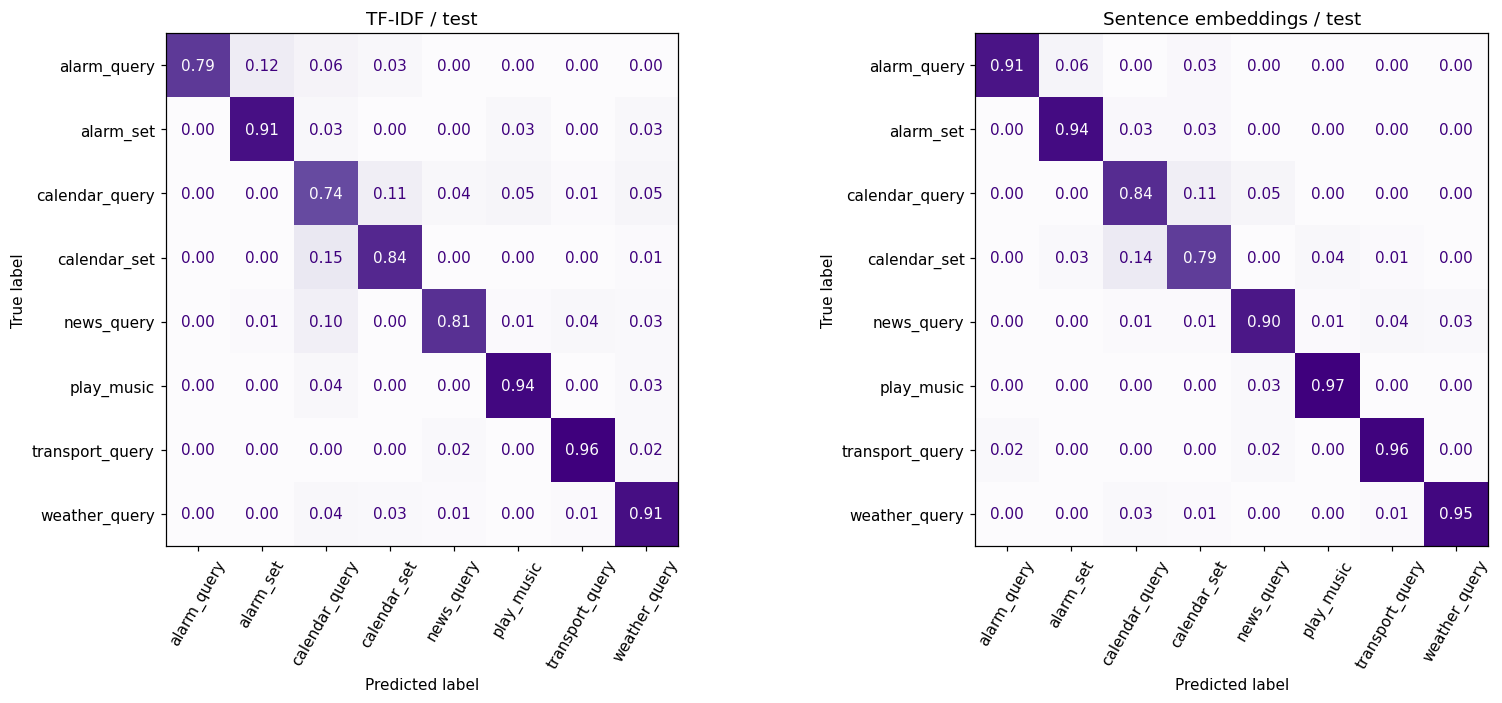

In [23]:
class_reports = {}
for name, prediction in [
    ("TF-IDF", tfidf_test_prediction), ("Sentence embeddings", embedding_test_prediction)
]:
    report = pd.DataFrame(classification_report(
        y_test, prediction, labels=LABELS, output_dict=True, zero_division=0
    )).T
    class_reports[name] = report
    display(Markdown(f"**{name}: test**"))
    display(report.loc[LABELS, ["precision", "recall", "f1-score", "support"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for axis, (name, prediction) in zip(axes, [
    ("TF-IDF", tfidf_test_prediction), ("Sentence embeddings", embedding_test_prediction)
]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, prediction, labels=LABELS, normalize="true",
        ax=axis, cmap="Purples", colorbar=False, values_format=".2f",
        xticks_rotation=60,
    )
    axis.set_title(name + " / test")
plt.tight_layout()
plt.show()

### 9.2. Качество, время и размер representations

Сравнение matrices ниже не включает model weights, vocabulary и накладные
расходы Python. Размер dense matrix не равен полному размеру решения.
У encoder отдельно учитывается загрузка checkpoint; её не стоит включать
в latency каждого последующего запроса.

`cache_hit=True` означает чтение заранее вычисленных embeddings.
Такое время нельзя называть скоростью inference. По этой причине таблица
явно показывает cache status. Кроме того, lexical features/classifier
работают на CPU, а encoder может работать на GPU.

In [24]:
display(pd.DataFrame([
    {"representation": "TF-IDF", "train_dimensions": X_train_tfidf.shape[1],
     "train_matrix_MiB": sparse_megabytes(X_train_tfidf)},
    {"representation": "Sentence embeddings", "train_dimensions": train_embeddings.shape[1],
     "train_matrix_MiB": train_embeddings.nbytes / 1024**2},
]).round(3))
display(pd.DataFrame([
    {"stage": "TF-IDF train+dev feature extraction", "seconds": tfidf_feature_seconds, "cache_hit": False},
    {"stage": "Encoder train", "seconds": train_encoding["seconds"], "cache_hit": train_encoding["cache_hit"]},
    {"stage": "Encoder dev", "seconds": dev_encoding["seconds"], "cache_hit": dev_encoding["cache_hit"]},
    {"stage": "TF-IDF transform + classifier / test", "seconds": tfidf_test_seconds, "cache_hit": False},
    {"stage": "Encoder test", "seconds": test_encoding["seconds"], "cache_hit": test_encoding["cache_hit"]},
    {"stage": "Embedding classifier / test", "seconds": embedding_head_seconds, "cache_hit": False},
]).round(3))

,representation,train_dimensions,train_matrix_MiB
0,TF-IDF,1786,0.151
1,Sentence embeddings,384,2.194


,stage,seconds,cache_hit
0,TF-IDF train+dev feature extraction,0.043,False
1,Encoder train,0.860,False
2,Encoder dev,0.158,False
3,TF-IDF transform + classifier / test,0.010,False
4,Encoder test,0.243,False
5,Embedding classifier / test,0.001,False


<a id="errors"></a>
## 10. Error analysis

Общая metric отвечает, сколько ошибок сделано, но не объясняет, почему.
Соберём текст, reference label и predictions двух решений. Особенно полезны
случаи, где один метод ошибся, а другой ответил правильно.

Для каждой ошибки попробуйте выбрать объяснение:

- не хватает lexical overlap с training examples;
- class отличается действием, а не темой;
- формулировка неоднозначна даже для человека;
- присутствуют редкое имя, опечатка, число или непривычная конструкция;
- разметка вызывает сомнение;
- classifier уверенно выбирает известный class для неподходящего запроса.

Эти категории — гипотезы для анализа, а не автоматически установленные
причины. После просмотра test не используйте те же примеры для нового
подбора модели и заявления об «улучшении на независимом test».

In [25]:
analysis = test_df[["id", "text", "label"]].copy()
analysis["TF-IDF"] = tfidf_test_prediction
analysis["embeddings"] = embedding_test_prediction
analysis["tfidf_correct"] = analysis["TF-IDF"].eq(analysis["label"])
analysis["embedding_correct"] = analysis["embeddings"].eq(analysis["label"])

groups = {
    "TF-IDF ошибся; embeddings верны":
        ~analysis["tfidf_correct"] & analysis["embedding_correct"],
    "TF-IDF верен; embeddings ошиблись":
        analysis["tfidf_correct"] & ~analysis["embedding_correct"],
    "Оба решения ошиблись":
        ~analysis["tfidf_correct"] & ~analysis["embedding_correct"],
}
for name, mask in groups.items():
    display(Markdown(f"**{name}: {int(mask.sum())} примеров**"))
    display(analysis.loc[mask, ["text", "label", "TF-IDF", "embeddings"]].head(6))

**TF-IDF ошибся; embeddings верны: 50 примеров**

,text,label,TF-IDF,embeddings
2,надо ли мне открыть люк на крыше,weather_query,calendar_query,weather_query
3,предупреди меня пожалуйста за день до дня рождения евгения,calendar_set,calendar_query,calendar_set
10,в кирове сильная жара,weather_query,calendar_set,weather_query
13,ты не мог бы перенести мою встречу,calendar_query,play_music,calendar_query
30,экономические отношения,news_query,calendar_query,news_query
32,я хочу знать больше об этом событии,calendar_query,play_music,calendar_query


**TF-IDF верен; embeddings ошиблись: 28 примеров**

,text,label,TF-IDF,embeddings
6,установи напоминание о спортивной игре,calendar_set,calendar_set,calendar_query
21,создай напоминание для стирки в восемь вечера,calendar_set,calendar_set,alarm_set
27,привет google включи плейлист дурацкий в моем приложении gaana,play_music,play_music,news_query
34,какие события произойдут сегодня,calendar_query,calendar_query,news_query
76,где состоится моя встреча в девять утра,calendar_query,calendar_query,calendar_set
100,расскажи мне быстро о наградах академии,news_query,news_query,calendar_set


**Оба решения ошиблись: 23 примеров**

,text,label,TF-IDF,embeddings
1,получить оценки,weather_query,calendar_set,calendar_query
38,открой время встречи,calendar_query,calendar_set,calendar_set
73,что происходит четвертого декабря,calendar_query,news_query,news_query
105,olly сегодня вечером в девять в джаз клубе играет хорошая группа я хочу пойти,calendar_set,weather_query,play_music
131,я иногда обращаю внимание,weather_query,calendar_query,calendar_query
179,не забыл ли я поставить напоминание для следующей записи к врачу,alarm_query,calendar_set,calendar_set


### 10.1. Ошибки с высоким score

Посмотрим несколько ошибок с наибольшим `predict_proba` у embedding
classifier. Эта величина относится к известным classes и не гарантирует
калиброванную уверенность. Высокий score возможен при ошибке и при
неподходящем входе.

Отбор ошибок ниже используется только для качественного разбора.
Не выбирайте threshold по этим test examples. Для такого решения требуется
отдельный validation protocol, включающий out-of-scope запросы.

In [26]:
test_probabilities = embedding_classifier.predict_proba(test_embeddings)
analysis["embedding_max_probability"] = test_probabilities.max(axis=1)
confident_errors = (
    analysis.loc[~analysis["embedding_correct"]]
    .sort_values("embedding_max_probability", ascending=False)
)
display(confident_errors[["text", "label", "embeddings", "embedding_max_probability"]].head(8))

,text,label,embeddings,embedding_max_probability
152,мне нужно подтвердить все встречи на сегодня можешь пригласить человека,calendar_query,calendar_set,0.958988
200,информация о недавних событиях,calendar_query,news_query,0.907080
38,открой время встречи,calendar_query,calendar_set,0.904301
361,где находится общественная библиотека,transport_query,news_query,0.876050
301,василий свадьба напоминание,calendar_query,calendar_set,0.830914
437,правда ли что день благодарения четырнадцатого в этом месяце,calendar_query,calendar_set,0.830786
347,открой напоминания,calendar_query,calendar_set,0.830068
341,настройки будильника,alarm_query,alarm_set,0.816202


## 11. Предсказания для новых запросов

Ниже небольшие авторские probes, которые не использовались при выборе
параметров. Последний запрос намеренно находится вне выбранных восьми intents.
Оба classifier всё равно вернут один из известных labels.

Сравните «создай» и «покажи». Затем придумайте собственную пару с отрицанием
или опечаткой. Изменение предсказания на одной фразе не заменяет evaluation,
но помогает формулировать проверяемые гипотезы о поведении системы.

In [27]:
new_queries = [
    "Поставь будильник на семь утра",
    "Какие будильники у меня включены",
    "Добавь встречу с коллегами завтра в десять",
    "Покажи встречи на завтра",
    "Какая погода ожидается в Казани",
    "Включи спокойную музыку",
    "Объясни доказательство теоремы Пифагора",
]
new_vectors = encoder.encode(new_queries, normalize_embeddings=True, convert_to_numpy=True)
new_probabilities = embedding_classifier.predict_proba(new_vectors)
display(pd.DataFrame({
    "text": new_queries,
    "TF-IDF": tfidf_pipeline.predict(new_queries),
    "embeddings": embedding_classifier.predict(new_vectors),
    "embedding_max_probability": new_probabilities.max(axis=1).round(3),
}))

,text,TF-IDF,embeddings,embedding_max_probability
0,Поставь будильник на семь утра,alarm_set,alarm_set,0.981
1,Какие будильники у меня включены,alarm_query,alarm_query,0.985
2,Добавь встречу с коллегами завтра в десять,calendar_set,calendar_set,0.890
3,Покажи встречи на завтра,calendar_query,calendar_query,0.690
4,Какая погода ожидается в Казани,weather_query,weather_query,0.992
5,Включи спокойную музыку,play_music,play_music,0.999
6,Объясни доказательство теоремы Пифагора,calendar_query,play_music,0.569


<a id="exercises"></a>
## 12. Дополнительные упражнения

Эти упражнения не являются согласованным ДЗ1: они предназначены для работы
внутри семинара и самостоятельного закрепления. Сроков и системы оценивания
они не устанавливают.

**Задание 1. Tokenization и отрицание.** Возьмите пару «включи музыку» /
«не включай музыку». Сравните NLTK tokens, spaCy lemmas и удаление stop words.
Объясните, какие различия сохраняются. Не оценивайте качество tokenizer
только по тому, совпадают ли его tokens с пробелами.

**Задание 2. Word и character n-grams.** При фиксированном `C=1` сравните
word TF-IDF и `char_wb` TF-IDF на dev. Для второго используйте
`ngram_range=(3, 5)`, `min_df=2`, `max_features=30_000`.
Обсудите vocabulary size и возможную устойчивость к опечаткам.

**Задание 3. Проверка ошибки.** Возьмите один disagreement двух методов.
Сформулируйте две возможные причины и предложите новый validation example,
который поможет их различить.

**Задание 4. Data leakage.** Объясните, почему
`vectorizer.fit_transform(train + test)` нарушает protocol даже без
использования test labels. Укажите, какая статистика при этом изменилась.

**Задание 5. Семантическое соседство.** Найдите ближайшие training examples
к новому запросу с помощью embeddings. Проверьте, одинаковы ли их intents.
Объясните, почему nearest neighbor не обязательно является правильным
ответом classifier.

Решения и рабочие примеры расположены ниже. Сначала сформулируйте собственный
ответ; при проведении занятия можно свернуть эти code cells.

### 12.1. Решение задания 1

Сравниваем две разные операции: преобразование словоформ и удаление элементов.
Lemmatization может сближать глагольные формы, а удаление отрицания способно
менять смысл. Конкретные outputs зависят от языковой модели и ресурса
stop words, поэтому они выводятся явно.

In [28]:
exercise_texts = ["Включи музыку", "Не включай музыку"]
display(pd.DataFrame({
    "text": exercise_texts,
    "NLTK_tokens": [wordpunct_tokenize(t.lower()) for t in exercise_texts],
    "spaCy_lemmas": lemmatize_texts(exercise_texts),
    "default_stopwords": [remove_stopwords(t, ru_stopwords) for t in exercise_texts],
    "keep_negations": [remove_stopwords(t, safe_stopwords) for t in exercise_texts],
}))

,text,NLTK_tokens,spaCy_lemmas,default_stopwords,keep_negations
0,Включи музыку,"[включи, музыку]",включи музыка,включи музыку,включи музыку
1,Не включай музыку,"[не, включай, музыку]",не включай музыка,включай музыку,не включай музыку


### 12.2. Решение задания 2

Этот дополнительный пример оценивает только dev и не меняет уже
зафиксированный основной test result. `char_wb` строит character n-grams
внутри границ слов с padding по краям. Он может использовать повторяющиеся
части слов, но увеличение feature space не гарантирует лучшего качества.

In [29]:
character_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char_wb", ngram_range=(3, 5), min_df=2,
        max_features=30_000, sublinear_tf=True,
    )),
    ("classifier", LogisticRegression(C=1.0, max_iter=2000, random_state=SEED)),
])
character_pipeline.fit(X_train, y_train)
char_dev_prediction = character_pipeline.predict(X_dev)
display(pd.DataFrame([
    {"features": "word (1, 2)", "C": 1,
     "dev_macro_F1": raw_c1["macro_F1"], "vocabulary_size": len(vectorizer.vocabulary_)},
    {"features": "char_wb (3, 5)", "C": 1,
     "dev_macro_F1": f1_score(y_dev, char_dev_prediction, average="macro", zero_division=0),
     "vocabulary_size": len(character_pipeline.named_steps["tfidf"].vocabulary_)},
]).round(4))

,features,C,dev_macro_F1,vocabulary_size
0,"word (1, 2)",1,0.8709,1786
1,"char_wb (3, 5)",1,0.8962,8662


### 12.3. Обсуждение заданий 3 и 4

**Error analysis.** Если TF-IDF ошибается на paraphrase, возможны как минимум
две гипотезы: отсутствует нужный lexical overlap либо пример действительно
неоднозначен по label. Проверьте несколько переформулировок с сохранением
действия и несколько фраз, где меняется только действие. Не выводите причину
из одного наблюдения.

**Data leakage.** При `fit` на train+test vocabulary и document frequencies
содержат сведения о будущих test inputs. Даже без labels модель получает
статистику evaluation corpus. В нашем protocol `fit` относится к train;
для dev/test выполняется `transform`. Если используется cross-validation,
vectorizer должен обучаться внутри каждого training fold через Pipeline.

В отдельной transductive постановке доступ к неразмеченным evaluation inputs
может быть разрешён заранее, но это другой protocol. Мы его не используем.

## 13. Дополнение: nearest neighbors и связь с semantic search

Classifiers и retrieval используют vectors по-разному. Classifier обучает
decision boundary по labels. Retrieval ранжирует элементы corpus по
similarity с query. Здесь просто найдём похожие training examples.

Поскольку vectors нормализованы, `train_embeddings @ query_vector`
вычисляет cosine similarity. Никакого дополнительного обучения на labels
при этом нет. На небольшой коллекции exact search достаточно; отдельная
vector database не требуется.

Обратите внимание: выбранный checkpoint — general sentence encoder.
Этот пример показывает механику retrieval, а не обещает оптимальность
модели для поиска длинных документов или RAG.

In [30]:
query = "На какое время у меня поставлен будильник?"
query_vector = encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True)[0]
similarities = train_embeddings @ query_vector
top_indices = np.argsort(-similarities, kind="stable")[:5]
neighbors = train_df.iloc[top_indices][["text", "label"]].copy()
neighbors["cosine_similarity"] = similarities[top_indices]
print("Query:", query)
display(neighbors.reset_index(drop=True).round(4))

Query: На какое время у меня поставлен будильник?


,text,label,cosine_similarity
0,на какое время установлен мой будильник,alarm_query,0.9732
1,на какое время установлен будильник,alarm_query,0.9541
2,во сколько сегодня зазвенит мой будильник,alarm_query,0.9469
3,на какое время установлены мои будильники,alarm_query,0.9386
4,в какое время меня разбудит будильник,alarm_query,0.9365


## 14. Сохранение результатов и воспроизводимость

Notebook сохраняет таблицы metrics и predictions, а также manifest:
версии библиотек, источник и checksum данных, выбранные IDs, параметры
representations и `C`. Идентификаторы примеров позволяют восстановить именно
тот split, который был использован.

Это промежуточные файлы вашей рабочей сессии в `seminar_work/results`;
отдельные файлы не нужны для чтения самого notebook. Embedding cache
можно использовать при повторном запуске того же эксперимента, но при
изменении текстов или модели его ключ изменится.

In [31]:
selected_ids = {part: frame["id"].tolist() for part, frame in splits.items()}
split_digest = hashlib.sha256(
    json.dumps(selected_ids, sort_keys=True).encode("utf-8")
).hexdigest()
run_manifest = {
    "task": "MASSIVE Russian / educational 8-intent classification",
    "seed": SEED, "target_intents": TARGET_INTENTS,
    "cap_per_class": CAP_PER_CLASS, "selected_ids": selected_ids,
    "split_sha256": split_digest,
    "data_url": DATA_URL, "archive_sha256": ARCHIVE_SHA256,
    "ru_jsonl_sha256": hashlib.sha256(raw_bytes).hexdigest(),
    "model": ENCODING_CONFIG, "device": DEVICE, "versions": versions,
    "tfidf_C": tfidf_C, "embedding_C": embedding_C, "C_grid": C_GRID,
    "selection_metric": "dev macro-F1",
    "test_scores": test_scores.to_dict(orient="records"),
}
(RESULT_DIR / "run_manifest.json").write_text(
    json.dumps(run_manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)
test_scores.to_csv(RESULT_DIR / "test_metrics.csv", index=False)
analysis.to_csv(RESULT_DIR / "test_predictions.csv", index=False)
print("Сохранено:", RESULT_DIR.resolve())
print("Split SHA-256:", split_digest)

Сохранено: /work/seminar_work/results
Split SHA-256: f2951ee47bf53dda2c9e304e27b4eef9299f1b0bc3e65ce40d8269e77804c391


## 15. Контрольные вопросы и выводы

После семинара вы должны уметь объяснить и выполнить следующие действия:

1. Определить input, target и единицу наблюдения для text classification.
2. Различить train, dev и test; обнаружить точные повторы между ними.
3. Сравнить tokenization, stemming и lemmatization на конкретной фразе.
4. Объяснить риск удаления stop words на примере отрицания.
5. Построить TF-IDF без обучения vocabulary и IDF на test.
6. Обучить Logistic Regression и выбрать `C` по dev.
7. Получить frozen sentence embeddings с сохранением порядка примеров.
8. Сопоставить accuracy, macro-F1, class-wise metrics и confusion matrix.
9. Найти ошибки двух решений и сформулировать проверяемую гипотезу.
10. Объяснить различие classifier prediction и nearest-neighbor retrieval.

**Краткий отчёт по своему запуску:** запишите размеры split, выбранные `C`,
test macro-F1 обоих решений и два примера ошибок. Отдельно укажите, какой
вывод поддерживают данные, а какой требует дополнительной проверки.
Например, результат на восьми intents не отвечает на вопрос о всех задачах NLP.

Возвращаясь к двум лекциям: preprocessing задаёт наблюдаемые признаки;
representation превращает текст в численный input; classifier обучается
использовать этот input для labels. Качество оценивается на отдельной выборке,
а выбор representation проверяется сравнением, а не названием метода.

## 16. Если что-то не запускается

| Симптом | Что проверить |
|---|---|
| `ModuleNotFoundError` | Выполнена ли установка в том же kernel; запущена ли первая ячейка |
| Ошибка NumPy/бинарной совместимости после установки | Перезапустить runtime; использовать чистое окружение Python 3.10–3.12 |
| spaCy не находит `ru_core_news_sm` | Установить wheel из первой ячейки и перезапустить kernel |
| NLTK не находит `stopwords` | Выполнить ячейку `nltk.download`, проверить интернет |
| Timeout при загрузке MASSIVE/model | Повторить после восстановления соединения; данные берутся с публичных источников |
| Checksum архива не совпадает | Удалить только повреждённый файл архива из cache и повторить загрузку |
| `CUDA out of memory` | Уменьшить batch size до 8 или перед созданием encoder выбрать `DEVICE="cpu"` |
| Embeddings считаются медленно | Проверить `DEVICE`; дождаться первого прохода, последующие могут использовать cache |
| `NameError` для переменной | Выполнить пропущенные ячейки с начала; не запускать разделы в произвольном порядке |
| Метрики отличаются от сохранённого output | Сверить versions, split digest, model revision, параметры и изменённые ячейки |

Не заменяйте неудавшуюся загрузку искусственным датасетом незаметно:
это изменит задачу и сделает результаты несопоставимыми. Для занятия
преподаватель должен заранее выполнить полный проход в целевом окружении.

## Источники и документация

- Программа занятия: [блок 1, занятие 3](https://docs.google.com/document/d/1dhTfnnaMGqnamn8odhJQwGDgKYyPB46GE1Q-YxJ3D-U/edit).
- FitzGerald et al. **MASSIVE** (2022):
  [paper](https://arxiv.org/abs/2204.08582), [официальные данные и README](https://github.com/alexa/massive).
- Bastianelli et al. **SLURP** (2020):
  [paper](https://aclanthology.org/2020.emnlp-main.588/).
- NLTK: [tokenize](https://www.nltk.org/api/nltk.tokenize.html),
  [SnowballStemmer](https://www.nltk.org/api/nltk.stem.snowball.html).
- spaCy: [Russian models](https://spacy.io/models/ru),
  [processing pipelines](https://spacy.io/usage/processing-pipelines).
- scikit-learn:
  [TfidfVectorizer](https://scikit-learn.org/1.7/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html),
  [LogisticRegression](https://scikit-learn.org/1.7/modules/generated/sklearn.linear_model.LogisticRegression.html),
  [data leakage и Pipeline](https://scikit-learn.org/1.7/common_pitfalls.html).
- Sentence Transformers:
  [model card](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2),
  [encode API](https://www.sbert.net/docs/package_reference/sentence_transformer/SentenceTransformer.html),
  [semantic textual similarity](https://www.sbert.net/docs/sentence_transformer/usage/semantic_textual_similarity.html).
- Материалы к лекциям:
  [Yandex School of Data Analysis NLP course](https://github.com/yandexdataschool/nlp_course),
  [Elena Voita — Word Embeddings](https://lena-voita.github.io/nlp_course/word_embeddings.html).

Авторские учебные объяснения и probes: Алан-Барсаг Газзаев, материалы занятия.
Тексты corpus, модель и библиотеки имеют собственных авторов и licenses,
указанных в соответствующих источниках.